In [1]:
import cv2

In [8]:
cap = cv2.VideoCapture(0)
ret, frame = cap.read()
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
small = cv2.resize(gray, (64,64))

print(small)

[[ 63  77  85 ... 101 176  89]
 [ 63  74  78 ... 105 184  81]
 [ 62  76  77 ... 105 174  83]
 ...
 [ 23  21  16 ... 167 169  46]
 [ 26  16  21 ... 172 167 151]
 [ 21  16  27 ... 165 152 150]]


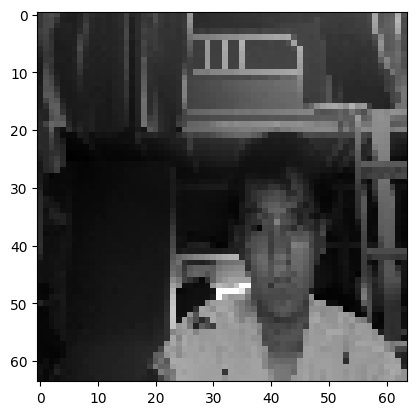

In [13]:
import matplotlib.pyplot as plt

plt.imshow(small, cmap='gray')
plt.show()

In [ ]:
import onnxruntime
import numpy as np

ort_session = onnxruntime.InferenceSession("mobilenetv2_face.onnx")

# 将张量转化为ndarray格式
def to_numpy(tensor):
    return tensor.detach().cpu().numpy() if tensor.requires_grad else tensor.cpu().numpy()

input_data = small.astype(np.float32)[None, None, :, :]

# 构建输入的字典和计算输出结果
ort_inputs = {ort_session.get_inputs()[0].name: input_data}
ort_outs = ort_session.run(None, ort_inputs)

# 打印输出结果
print(ort_outs)
# 释放摄像头
cap.release()
cv2.destroyAllWindows()

[array([[-6.898459,  6.784107]], dtype=float32)]
